# ReviewMind AI — Universal Edition

### Universal Customer Feedback Intelligence Platform

An NLP-powered platform for sentiment analysis, emotion detection,
topic discovery, and customer feedback intelligence.

## 1. Project Setup and Dataset Inspection

## Notebook scope and workflow

This notebook develops and evaluates two sentiment-classification approaches for **ReviewMind AI** using the IMDb review dataset as a reproducible text-classification benchmark. The workflow moves from data inspection and cleaning to a TF-IDF baseline, then to a fine-tuned DistilBERT model, followed by error analysis, comparison, and model persistence.

The notebook is exploratory and educational: the recorded outputs are the source of truth for the observations below. No claims are made beyond the displayed experiments.



### 1.1 Import Required Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import os

print("Python Version:", sys.version)
print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)

print("\nReviewMind AI environment is ready!")

Python Version: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
Pandas Version: 3.1.1
NumPy Version: 2.4.6

ReviewMind AI environment is ready!


The first code cell verifies the local Python and core numerical-visualization environment. The imports are used by later sections: pandas and NumPy support data work, matplotlib and seaborn support plots, and `sys`/`os` support environment and artifact checks.



### 1.2 Load the IMDb Dataset

Load the IMDb movie review dataset and inspect its structure, columns, and sample records.

In [6]:
data = pd.read_csv("../data/raw/IMDB Dataset.csv")

display(data.head())

print("Dataset Shape:", data.shape)

print("\nColumn Names:")
print(data.columns.tolist())

print("\nDataset Information:")
data.info()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


Dataset Shape: (50000, 2)

Column Names:
['review', 'sentiment']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB


The raw dataset contains 50,000 reviews and two columns: `review` and `sentiment`. Both columns are present and non-null in the recorded profile. The labels are textual (`positive` and `negative`) and are converted to binary values before model training.



### 1.3 Data Quality Inspection

Check for missing values, duplicate reviews, and the distribution of sentiment labels.

In [ ]:
print("Missing Values:")
print(data.isnull().sum())

print("\nDuplicate Rows:", data.duplicated().sum())

print("\nSentiment Distribution:")
print(data["sentiment"].value_counts())

print("\nSentiment Percentages:")
print(data["sentiment"].value_counts(normalize=True) * 100)

Missing Values:
review       0
sentiment    0
dtype: int64

Duplicate Rows: 418

Sentiment Distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Sentiment Percentages:
sentiment
positive    50.0
negative    50.0
Name: proportion, dtype: float64


The dataset is initially balanced: 25,000 positive and 25,000 negative reviews. There are 418 duplicate rows and no missing values. Removing duplicates later prevents repeated examples from influencing the fitted models.



### 1.4 Sentiment Distribution Visualization

Visualize the distribution of positive and negative reviews to understand whether the dataset is balanced.

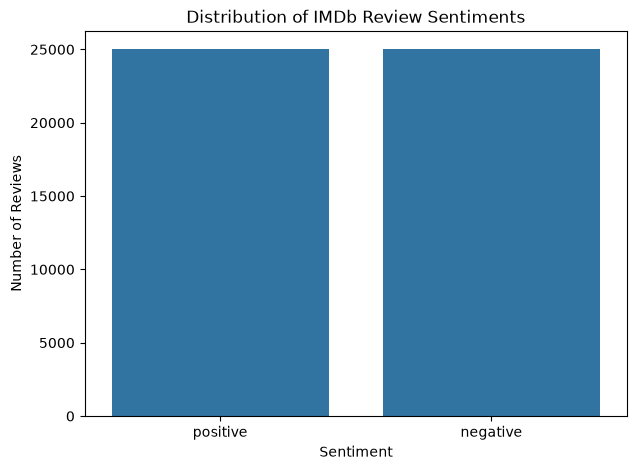

In [8]:
plt.figure(figsize=(7, 5))

sns.countplot(data=data, x="sentiment")

plt.title("Distribution of IMDb Review Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

### 1.5 Text Data Cleaning

In [9]:
data = data.drop_duplicates()

data = data.dropna(subset=["review", "sentiment"])

data = data.reset_index(drop=True)

print("Dataset shape after cleaning:", data.shape)
print("\nMissing values:")
print(data.isnull().sum())

print("\nDuplicate rows:", data.duplicated().sum())

Dataset shape after cleaning: (49582, 2)

Missing values:
review       0
sentiment    0
dtype: int64

Duplicate rows: 0


Cleaning removes duplicate rows, drops records missing either required field, and resets the index. The resulting dataset has 49,582 reviews and no remaining duplicates or missing values. The `<br />` markup is replaced with spaces before vectorization so HTML line breaks do not become model features.



### 1.6 Review Length Analysis

Analyze the length of customer reviews to understand text characteristics and determine suitable input lengths for NLP models.

Review Length Statistics:
count    49582.000000
mean       231.350167
std        171.542020
min          4.000000
25%        126.000000
50%        173.000000
75%        281.000000
max       2470.000000
Name: review_length, dtype: float64


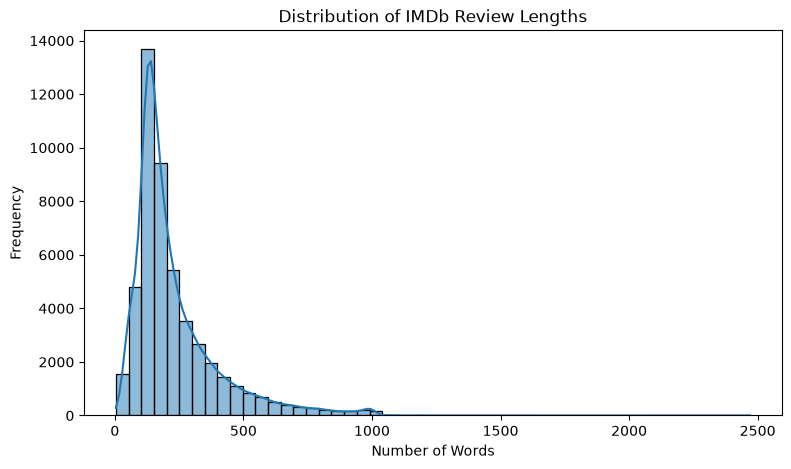

In [ ]:
data["review_length"] = data["review"].apply(
    lambda review: len(review.split())
)

print("Review Length Statistics:")
print(data["review_length"].describe())

plt.figure(figsize=(9, 5))

sns.histplot(
    data=data,
    x="review_length",
    bins=50,
    kde=True
)

plt.title("Distribution of IMDb Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()

Review lengths are summarized in words to understand the input distribution. The cleaned reviews average 231.35 words; the median is 173, the 90th percentile is 452, and the maximum is 2,470 words. These statistics provide context for the later transformer truncation length, which means some long reviews are necessarily shortened.



In [11]:
percentiles = data["review_length"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99]
)

print("Review Length Percentiles:")
print(percentiles)

print("\nAverage Review Length:",
      data["review_length"].mean())

print("\nLongest Review:",
      data["review_length"].max())

Review Length Percentiles:
0.50    173.0
0.75    281.0
0.90    452.0
0.95    591.0
0.99    908.0
Name: review_length, dtype: float64

Average Review Length: 231.35016739945948

Longest Review: 2470


In [ ]:
from sklearn.model_selection import train_test_split

X = data["review"].astype(str)

X = X.str.replace(r"<br\s*/?>", " ", regex=True)

y = data["sentiment"].map({
    "negative": 0,
    "positive": 1
})

print("Input samples:", len(X))
print("Target samples:", len(y))
print("\nLabel distribution:")
print(y.value_counts())

Input samples: 49582
Target samples: 49582

Label distribution:
sentiment
1    24884
0    24698
Name: count, dtype: int64


Reviews are split into inputs and labels, with `negative` mapped to 0 and `positive` mapped to 1. The split uses stratification and `random_state=42`, preserving the near-balanced label proportions while making the experiment reproducible.



In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nTesting label distribution:")
print(y_test.value_counts())

Training samples: 39665
Testing samples: 9917

Training label distribution:
sentiment
1    19907
0    19758
Name: count, dtype: int64

Testing label distribution:
sentiment
1    4977
0    4940
Name: count, dtype: int64


In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (39665, 30000)
Testing TF-IDF shape: (9917, 30000)


### TF-IDF feature extraction

Term Frequency–Inverse Document Frequency (TF-IDF) represents each review as a sparse vector. Unigrams and bigrams capture individual words and short phrases; `min_df=2` removes terms seen only once, `max_df=0.95` removes extremely common terms, and `max_features=30000` bounds the feature space. The vectorizer is fitted only on the training text and then applied to the test text to avoid test-set vocabulary leakage.



In [15]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


### Logistic Regression baseline

Logistic Regression learns a linear decision boundary over the TF-IDF vectors and produces both class predictions and probabilities. It is a useful, efficient baseline for sentiment because word and phrase weights remain relatively interpretable.



In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

y_pred = lr_model.predict(X_test_tfidf)

y_prob = lr_model.predict_proba(X_test_tfidf)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("LOGISTIC REGRESSION - MODEL PERFORMANCE")
print("----------------------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"]
))

LOGISTIC REGRESSION - MODEL PERFORMANCE
----------------------------------------
Accuracy:  0.9052
Precision: 0.8945
Recall:    0.9196
F1-Score:  0.9069
ROC-AUC:   0.9663

Classification Report:
              precision    recall  f1-score   support

    Negative       0.92      0.89      0.90      4940
    Positive       0.89      0.92      0.91      4977

    accuracy                           0.91      9917
   macro avg       0.91      0.91      0.91      9917
weighted avg       0.91      0.91      0.91      9917



### Evaluation metrics

Accuracy is the fraction of all correct predictions. Precision measures how often predicted positives are truly positive, while recall measures how many actual positives are found. F1 is the harmonic mean of precision and recall, and ROC-AUC summarizes ranking quality across probability thresholds. The classification report and confusion matrix provide class-level detail rather than relying on accuracy alone.

On the 9,917-review test split, Logistic Regression records accuracy **0.9052**, precision **0.8945**, recall **0.9196**, F1 **0.9069**, and ROC-AUC **0.9663**. The balanced supports make these aggregate results reasonably comparable across the two classes.



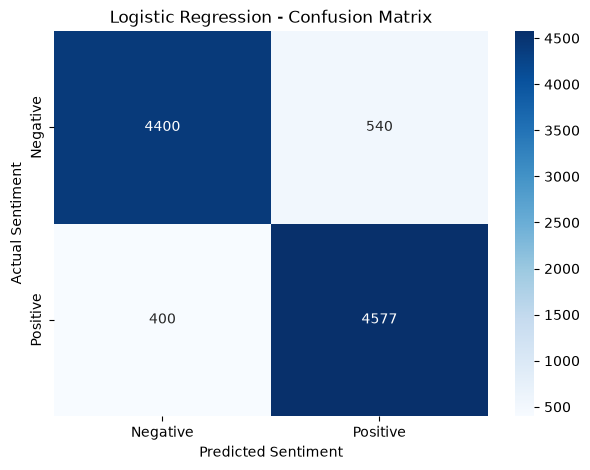

In [17]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.show()

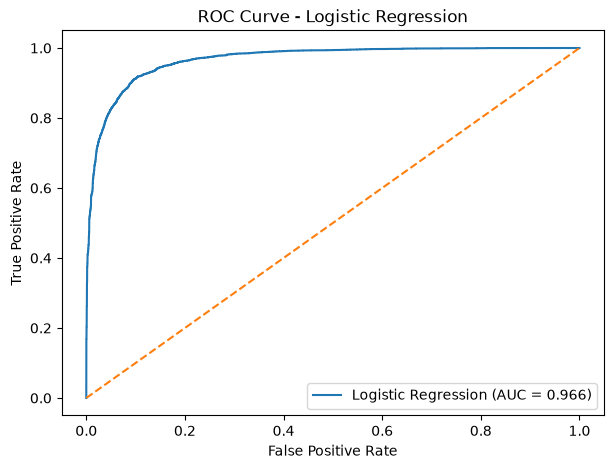

In [18]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.3f})"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.show()

In [ ]:
error_analysis = pd.DataFrame({
    "review": X_test.reset_index(drop=True),
    "actual": y_test.reset_index(drop=True),
    "predicted": y_pred,
    "positive_probability": y_prob
})

error_analysis["actual"] = error_analysis["actual"].map({
    0: "Negative",
    1: "Positive"
})

error_analysis["predicted"] = error_analysis["predicted"].map({
    0: "Negative",
    1: "Positive"
})

incorrect_predictions = error_analysis[
    error_analysis["actual"] != error_analysis["predicted"]
]

print("Total incorrect predictions:", len(incorrect_predictions))

print("\nFalse Positives:")
display(
    incorrect_predictions[
        (incorrect_predictions["actual"] == "Negative") &
        (incorrect_predictions["predicted"] == "Positive")
    ][["review", "actual", "predicted"]].head(5)
)

print("\nFalse Negatives:")
display(
    incorrect_predictions[
        (incorrect_predictions["actual"] == "Positive") &
        (incorrect_predictions["predicted"] == "Negative")
    ][["review", "actual", "predicted"]].head(5)
)

Total incorrect predictions: 940

False Positives:


,review,actual,predicted
24,Despite being a huge fan of Fred Astaire and G...,Negative,Positive
43,"OK, let me again admit that I haven't seen any...",Negative,Positive
78,I was excited to hear that someone had made a ...,Negative,Positive
79,"Using tons of stock footage, not only from Tra...",Negative,Positive
123,"Richard Dix is a big, not very nice industrial...",Negative,Positive



False Negatives:


,review,actual,predicted
15,"This isn't exactly a great film, but I admire ...",Positive,Negative
35,"Well, well....Roeg touched a bit of a nerve th...",Positive,Negative
45,"I'm not here to tell you ""Armored"" is Kubricki...",Positive,Negative
51,"this movie probably had a $750 budget, and sti...",Positive,Negative
106,"""Saving Grace"" is never riotously funny, but i...",Positive,Negative


### Error analysis

The error-analysis table pairs each test review with its actual label, prediction, and positive-class probability. There are **940 incorrect predictions**. The displayed false positives and false negatives are useful for investigating ambiguity, mixed sentiment, and language patterns that a linear bag-of-words model does not capture well.



In [ ]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

joblib.dump(
    {
        "vectorizer": tfidf,
        "model": lr_model
    },
    "../models/tfidf_logistic_regression.pkl")

print("Model saved successfully!")

Model saved successfully!


### Persisting the baseline

The fitted TF-IDF vectorizer and Logistic Regression model are saved together in `models/tfidf_logistic_regression.pkl`. Saving both objects is essential: the model expects the same vocabulary and feature mapping at inference time. The following cell reloads the pair and checks predictions on three example reviews.



In [21]:
saved_artifacts = joblib.load(
    "../models/tfidf_logistic_regression.pkl"
)

loaded_tfidf = saved_artifacts["vectorizer"]
loaded_model = saved_artifacts["model"]

sample_reviews = [
    "This movie was absolutely fantastic. I loved every moment!",
    "Terrible movie. The acting was boring and the story was awful.",
    "The movie had some good moments but the overall experience was disappointing."
]

sample_features = loaded_tfidf.transform(sample_reviews)

predictions = loaded_model.predict(sample_features)

for review, prediction in zip(sample_reviews, predictions):
    sentiment = "Positive" if prediction == 1 else "Negative"
    print(f"\nReview: {review}")
    print(f"Predicted Sentiment: {sentiment}")


Review: This movie was absolutely fantastic. I loved every moment!
Predicted Sentiment: Positive

Review: Terrible movie. The acting was boring and the story was awful.
Predicted Sentiment: Negative

Review: The movie had some good moments but the overall experience was disappointing.
Predicted Sentiment: Negative


In [23]:
import torch
import transformers
import accelerate

print("PyTorch Version:", torch.__version__)
print("Transformers Version:", transformers.__version__)
print("Accelerate Version:", accelerate.__version__)

print("CUDA Available:", torch.cuda.is_available())
print("Selected Device:", "CUDA" if torch.cuda.is_available() else "CPU")

PyTorch Version: 2.15.0+cpu
Transformers Version: 5.22.2
Accelerate Version: 1.15.0
CUDA Available: False
Selected Device: CPU


## DistilBERT fine-tuning

DistilBERT provides contextual token representations, allowing the classifier to use word meaning in context rather than only fixed word and phrase counts. The recorded environment uses CPU execution. The base checkpoint is loaded with a two-class classification head; the task-specific head is then fine-tuned on labeled reviews.



In [24]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

model_name = "distilbert/distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)

distilbert_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

device = torch.device("cpu")

distilbert_model.to(device)

print("DistilBERT tokenizer loaded successfully!")
print("DistilBERT model loaded successfully!")
print("Device:", device)
print("Number of labels:", distilbert_model.config.num_labels)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

c:\Users\ASUS\OneDrive\Desktop\ALL_AT_ONE_PLACE\ShadowFox\ShadowFox-ML-Internship\Advanced level\ReviewMind-AI\.venv311\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\ASUS\.cache\huggingface\hub\models--distilbert--distilbert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

c:\Users\ASUS\OneDrive\Desktop\ALL_AT_ONE_PLACE\ShadowFox\ShadowFox-ML-Internship\Advanced level\ReviewMind-AI\.venv311\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\ASUS\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT tokenizer loaded successfully!
DistilBERT model loaded successfully!
Device: cpu
Number of labels: 2


In [25]:
sample_text = "This movie was absolutely fantastic and entertaining!"

tokens = tokenizer(
    sample_text,
    padding="max_length",
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

print("Input IDs shape:", tokens["input_ids"].shape)
print("Attention Mask shape:", tokens["attention_mask"].shape)

print("\nTokenized words:")
print(tokenizer.convert_ids_to_tokens(tokens["input_ids"][0]))

Input IDs shape: torch.Size([1, 128])
Attention Mask shape: torch.Size([1, 128])

Tokenized words:
['[CLS]', 'this', 'movie', 'was', 'absolutely', 'fantastic', 'and', 'entertaining', '!', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[

Tokenization converts text into model input IDs and an attention mask. The example demonstrates special tokens and padding. Later training uses a maximum sequence length of 192, so longer reviews are truncated and shorter reviews are padded to a uniform tensor shape.



In [ ]:
import pandas as pd
import torch
from torch.utils.data import TensorDataset

train_data = pd.DataFrame({
    "review": X_train,
    "label": y_train
})

test_data = pd.DataFrame({
    "review": X_test,
    "label": y_test
})

train_subset = (
    train_data.groupby("label", group_keys=False)
    .sample(n=2000, random_state=42)
    .reset_index(drop=True)
)

test_subset = (
    test_data.groupby("label", group_keys=False)
    .sample(n=500, random_state=42)
    .reset_index(drop=True)
)

print("Training subset:", train_subset.shape)
print("Testing subset:", test_subset.shape)

print("\nTraining labels:")
print(train_subset["label"].value_counts())

print("\nTesting labels:")
print(test_subset["label"].value_counts())

Training subset: (4000, 2)
Testing subset: (1000, 2)

Training labels:
label
0    2000
1    2000
Name: count, dtype: int64

Testing labels:
label
0    500
1    500
Name: count, dtype: int64


To make CPU fine-tuning practical, the notebook samples a balanced subset of 4,000 training reviews and 1,000 test reviews. This is a deliberate computational compromise, not a replacement for the full held-out evaluation performed later.



In [ ]:
MAX_LENGTH = 192

train_encodings = tokenizer(
    train_subset["review"].tolist(),
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH,
    return_tensors="pt"
)

test_encodings = tokenizer(
    test_subset["review"].tolist(),
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH,
    return_tensors="pt"
)

train_labels = torch.tensor(
    train_subset["label"].tolist(),
    dtype=torch.long
)

test_labels = torch.tensor(
    test_subset["label"].tolist(),
    dtype=torch.long
)

train_dataset = TensorDataset(
    train_encodings["input_ids"],
    train_encodings["attention_mask"],
    train_labels
)

test_dataset = TensorDataset(
    test_encodings["input_ids"],
    test_encodings["attention_mask"],
    test_labels
)

print("Training dataset ready:", len(train_dataset))
print("Testing dataset ready:", len(test_dataset))
print("Input tensor shape:", train_encodings["input_ids"].shape)

Training dataset ready: 4000
Testing dataset ready: 1000
Input tensor shape: torch.Size([4000, 192])


In [ ]:
from torch.utils.data import DataLoader
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup

BATCH_SIZE = 16
EPOCHS = 2
LEARNING_RATE = 2e-5

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

optimizer = AdamW(
    distilbert_model.parameters(),
    lr=LEARNING_RATE
)

total_steps = len(train_loader) * EPOCHS
warmup_steps = int(0.1 * total_steps)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

print("Training configuration ready!")
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Total training steps:", total_steps)
print("Learning rate:", LEARNING_RATE)

Training configuration ready!
Batch size: 16
Epochs: 2
Total training steps: 500
Learning rate: 2e-05


The recorded fine-tuning configuration uses batch size 16, two epochs, learning rate `2e-5`, AdamW optimization, linear warmup, and gradient clipping. These settings are kept exactly as executed; the purpose here is to explain their role, not to retune the model.



In [29]:
import time
from torch.nn.utils import clip_grad_norm_

training_history = []

distilbert_model.train()

for epoch in range(EPOCHS):

    total_loss = 0
    start_time = time.time()

    print(f"\nStarting Epoch {epoch + 1}/{EPOCHS}")

    for step, batch in enumerate(train_loader):

        input_ids, attention_mask, labels = [
            item.to(device) for item in batch
        ]

        optimizer.zero_grad()

        outputs = distilbert_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss

        loss.backward()

        clip_grad_norm_(
            distilbert_model.parameters(),
            max_norm=1.0
        )

        optimizer.step()
        scheduler.step()

        total_loss += loss.item()

        if (step + 1) % 25 == 0:
            print(
                f"Epoch {epoch + 1} | "
                f"Batch {step + 1}/{len(train_loader)} | "
                f"Loss: {loss.item():.4f}"
            )

    average_loss = total_loss / len(train_loader)
    elapsed_time = time.time() - start_time

    training_history.append({
        "epoch": epoch + 1,
        "training_loss": average_loss,
        "time_seconds": elapsed_time
    })

    print(f"\nEpoch {epoch + 1} completed!")
    print(f"Average Training Loss: {average_loss:.4f}")
    print(f"Time Taken: {elapsed_time / 60:.2f} minutes")

print("\nDistilBERT fine-tuning completed!")


Starting Epoch 1/2
Epoch 1 | Batch 25/250 | Loss: 0.6931
Epoch 1 | Batch 50/250 | Loss: 0.6606
Epoch 1 | Batch 75/250 | Loss: 0.3183
Epoch 1 | Batch 100/250 | Loss: 0.6662
Epoch 1 | Batch 125/250 | Loss: 0.1789
Epoch 1 | Batch 150/250 | Loss: 0.3081
Epoch 1 | Batch 175/250 | Loss: 0.1475
Epoch 1 | Batch 200/250 | Loss: 0.2166
Epoch 1 | Batch 225/250 | Loss: 0.1321
Epoch 1 | Batch 250/250 | Loss: 0.1239

Epoch 1 completed!
Average Training Loss: 0.4410
Time Taken: 17.83 minutes

Starting Epoch 2/2
Epoch 2 | Batch 25/250 | Loss: 0.2440
Epoch 2 | Batch 50/250 | Loss: 0.4404
Epoch 2 | Batch 75/250 | Loss: 0.2453
Epoch 2 | Batch 100/250 | Loss: 0.5596
Epoch 2 | Batch 125/250 | Loss: 0.2834
Epoch 2 | Batch 150/250 | Loss: 0.1424
Epoch 2 | Batch 175/250 | Loss: 0.2482
Epoch 2 | Batch 200/250 | Loss: 0.0509
Epoch 2 | Batch 225/250 | Loss: 0.3888
Epoch 2 | Batch 250/250 | Loss: 0.2220

Epoch 2 completed!
Average Training Loss: 0.2297
Time Taken: 17.88 minutes

DistilBERT fine-tuning completed!

,epoch,training_loss,time_seconds
0,1,0.440977,1069.864923
1,2,0.229713,1072.799503


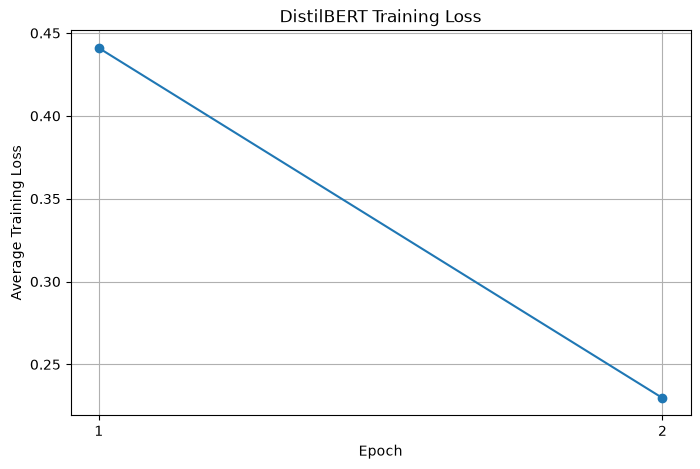

In [30]:
training_results = pd.DataFrame(training_history)

display(training_results)

plt.figure(figsize=(8, 5))

plt.plot(
    training_results["epoch"],
    training_results["training_loss"],
    marker="o"
)

plt.title("DistilBERT Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Average Training Loss")
plt.xticks(training_results["epoch"])
plt.grid(True)
plt.show()

Average training loss decreases from **0.4410** in epoch 1 to **0.2297** in epoch 2. This indicates learning on the training subset, but loss alone cannot establish generalization, so the held-out metrics in the next cells are the more important comparison.



In [31]:
import torch
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

distilbert_model.eval()

all_predictions = []
all_probabilities = []
all_actual = []

with torch.no_grad():

    for batch in test_loader:

        input_ids, attention_mask, labels = [
            item.to(device) for item in batch
        ]

        outputs = distilbert_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        probabilities = torch.softmax(outputs.logits, dim=1)

        predictions = torch.argmax(probabilities, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(
            probabilities[:, 1].cpu().numpy()
        )
        all_actual.extend(labels.cpu().numpy())


distilbert_predictions = np.array(all_predictions)
distilbert_probabilities = np.array(all_probabilities)
distilbert_actual = np.array(all_actual)

distilbert_metrics = {
    "Accuracy": accuracy_score(
        distilbert_actual, distilbert_predictions
    ),
    "Precision": precision_score(
        distilbert_actual, distilbert_predictions
    ),
    "Recall": recall_score(
        distilbert_actual, distilbert_predictions
    ),
    "F1 Score": f1_score(
        distilbert_actual, distilbert_predictions
    ),
    "ROC-AUC": roc_auc_score(
        distilbert_actual, distilbert_probabilities
    )
}

print("DISTILBERT TEST RESULTS")
print("-" * 40)

for metric, value in distilbert_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(
    distilbert_actual, distilbert_predictions
))

print("\nClassification Report:")
print(classification_report(
    distilbert_actual,
    distilbert_predictions,
    target_names=["Negative", "Positive"]
))

DISTILBERT TEST RESULTS
----------------------------------------
Accuracy: 0.8700
Precision: 0.8887
Recall: 0.8460
F1 Score: 0.8668
ROC-AUC: 0.9517

Confusion Matrix:
[[447  53]
 [ 77 423]]

Classification Report:
              precision    recall  f1-score   support

    Negative       0.85      0.89      0.87       500
    Positive       0.89      0.85      0.87       500

    accuracy                           0.87      1000
   macro avg       0.87      0.87      0.87      1000
weighted avg       0.87      0.87      0.87      1000



On the 1,000-review transformer subset, DistilBERT records accuracy **0.8700**, precision **0.8887**, recall **0.8460**, F1 **0.8668**, and ROC-AUC **0.9517**. The balanced confusion matrix shows 447 true negatives, 53 false positives, 77 false negatives, and 423 true positives.



In [32]:
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Use the complete original test split
full_test_texts = X_test.astype(str).tolist()
full_test_labels = torch.tensor(
    y_test.tolist(), dtype=torch.long
)

print("Preparing complete test dataset...")

full_test_encodings = tokenizer(
    full_test_texts,
    truncation=True,
    padding="max_length",
    max_length=192,
    return_tensors="pt"
)

full_test_dataset = TensorDataset(
    full_test_encodings["input_ids"],
    full_test_encodings["attention_mask"],
    full_test_labels
)

full_test_loader = DataLoader(
    full_test_dataset,
    batch_size=16,
    shuffle=False
)

print("Full test dataset:", len(full_test_dataset))

# Evaluate DistilBERT
distilbert_model.eval()

all_predictions = []
all_probabilities = []
all_actual = []

with torch.no_grad():

    for batch in full_test_loader:

        input_ids, attention_mask, labels = [
            item.to(device) for item in batch
        ]

        outputs = distilbert_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        probabilities = torch.softmax(outputs.logits, dim=1)
        predictions = torch.argmax(probabilities, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(
            probabilities[:, 1].cpu().numpy()
        )
        all_actual.extend(labels.cpu().numpy())

all_predictions = np.array(all_predictions)
all_probabilities = np.array(all_probabilities)
all_actual = np.array(all_actual)

full_distilbert_metrics = {
    "Accuracy": accuracy_score(all_actual, all_predictions),
    "Precision": precision_score(all_actual, all_predictions),
    "Recall": recall_score(all_actual, all_predictions),
    "F1 Score": f1_score(all_actual, all_predictions),
    "ROC-AUC": roc_auc_score(all_actual, all_probabilities)
}

print("\nDISTILBERT FULL TEST RESULTS")
print("-" * 45)

for metric, value in full_distilbert_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(all_actual, all_predictions))

print("\nClassification Report:")
print(classification_report(
    all_actual,
    all_predictions,
    target_names=["Negative", "Positive"]
))

Preparing complete test dataset...
Full test dataset: 9917

DISTILBERT FULL TEST RESULTS
---------------------------------------------
Accuracy: 0.8756
Precision: 0.8947
Recall: 0.8523
F1 Score: 0.8730
ROC-AUC: 0.9501

Confusion Matrix:
[[4441  499]
 [ 735 4242]]

Classification Report:
              precision    recall  f1-score   support

    Negative       0.86      0.90      0.88      4940
    Positive       0.89      0.85      0.87      4977

    accuracy                           0.88      9917
   macro avg       0.88      0.88      0.88      9917
weighted avg       0.88      0.88      0.88      9917



### Full test-set evaluation

The fine-tuned DistilBERT model is also evaluated on all 9,917 held-out reviews. It records accuracy **0.8756**, precision **0.8947**, recall **0.8523**, F1 **0.8730**, and ROC-AUC **0.9501**. This full-split result is the appropriate basis for comparison with Logistic Regression.



In [33]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Predict using the existing trained TF-IDF model
X_full_test_tfidf = tfidf.transform(X_test)

lr_full_predictions = lr_model.predict(X_full_test_tfidf)

lr_full_probabilities = lr_model.predict_proba(
    X_full_test_tfidf
)[:, 1]

# Calculate metrics
lr_full_metrics = {
    "Accuracy": accuracy_score(y_test, lr_full_predictions),
    "Precision": precision_score(y_test, lr_full_predictions),
    "Recall": recall_score(y_test, lr_full_predictions),
    "F1 Score": f1_score(y_test, lr_full_predictions),
    "ROC-AUC": roc_auc_score(y_test, lr_full_probabilities)
}

print("LOGISTIC REGRESSION FULL TEST RESULTS")
print("-" * 45)

for metric, value in lr_full_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, lr_full_predictions))

# Create model comparison
comparison = pd.DataFrame({
    "Metric": list(lr_full_metrics.keys()),
    "Logistic Regression": list(lr_full_metrics.values()),
    "DistilBERT": list(full_distilbert_metrics.values())
})

print("\nMODEL COMPARISON")
display(comparison.round(4))

LOGISTIC REGRESSION FULL TEST RESULTS
---------------------------------------------
Accuracy: 0.9052
Precision: 0.8945
Recall: 0.9196
F1 Score: 0.9069
ROC-AUC: 0.9663

Confusion Matrix:
[[4400  540]
 [ 400 4577]]

MODEL COMPARISON


,Metric,Logistic Regression,DistilBERT
0,Accuracy,0.9052,0.8756
1,Precision,0.8945,0.8947
2,Recall,0.9196,0.8523
3,F1 Score,0.9069,0.8730
4,ROC-AUC,0.9663,0.9501


### Model comparison

On the same full test split, Logistic Regression outperforms this DistilBERT run on accuracy (0.9052 vs 0.8756), recall (0.9196 vs 0.8523), F1 (0.9069 vs 0.8730), and ROC-AUC (0.9663 vs 0.9501). Precision is nearly tied, with DistilBERT marginally higher (0.8947 vs 0.8945). In this experiment, the simpler TF-IDF baseline is the stronger measured choice, while the transformer remains a useful contextual modeling option.



In [39]:
print("Model available:", "model" in globals())
print("Tokenizer available:", "tokenizer" in globals())

Model available: False
Tokenizer available: True


The verification cells inspect the names of model-related variables and confirm that the trained objects exist under their actual notebook variable names (`lr_model` and `distilbert_model`). The displayed `model available: False` refers only to the literal variable name `model`; it does not mean that the trained models are missing.



In [40]:
# Find variables that may contain a trained model
for name, obj in globals().copy().items():
    if any(word in name.lower() for word in ["model", "distil", "bert"]):
        print(
            "Variable:", name,
            "| Type:", type(obj).__name__
        )

Variable: lr_model | Type: LogisticRegression
Variable: loaded_model | Type: LogisticRegression
Variable: AutoModelForSequenceClassification | Type: type
Variable: model_name | Type: str
Variable: distilbert_model | Type: DistilBertForSequenceClassification
Variable: distilbert_predictions | Type: ndarray
Variable: distilbert_probabilities | Type: ndarray
Variable: distilbert_actual | Type: ndarray
Variable: distilbert_metrics | Type: dict
Variable: full_distilbert_metrics | Type: dict


In [42]:
import os

current_dir = os.getcwd()

if os.path.basename(current_dir).lower() == "notebooks":
    PROJECT_ROOT = os.path.abspath("..")
else:
    PROJECT_ROOT = current_dir

print("Project root:", PROJECT_ROOT)
print("Models folder exists:", os.path.isdir(os.path.join(PROJECT_ROOT, "models")))

Project root: c:\Users\ASUS\OneDrive\Desktop\ALL_AT_ONE_PLACE\ShadowFox\ShadowFox-ML-Internship\Advanced level\ReviewMind-AI
Models folder exists: True


In [43]:
import os

save_path = os.path.join(
    PROJECT_ROOT,
    "models",
    "distilbert_imdb_sentiment"
)

os.makedirs(save_path, exist_ok=True)

# Save the fine-tuned model and tokenizer
distilbert_model.save_pretrained(save_path)
tokenizer.save_pretrained(save_path)

print("Model and tokenizer saved successfully!")
print("Saved location:", save_path)
print("\nSaved files:")

for file in os.listdir(save_path):
    print("-", file)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model and tokenizer saved successfully!
Saved location: c:\Users\ASUS\OneDrive\Desktop\ALL_AT_ONE_PLACE\ShadowFox\ShadowFox-ML-Internship\Advanced level\ReviewMind-AI\models\distilbert_imdb_sentiment

Saved files:
- config.json
- model.safetensors
- tokenizer.json
- tokenizer_config.json


## Conclusion and limitations

ReviewMind AI now has a reproducible sentiment workflow: cleaned and stratified data, a strong TF-IDF/Logistic Regression baseline, a fine-tuned DistilBERT experiment, comparative metrics, error examples, and saved inference artifacts. The recorded results favor Logistic Regression for this dataset and execution configuration.

Important limitations are the IMDb-domain dataset, binary sentiment labels, truncation of long transformer inputs, CPU-oriented subset fine-tuning, and the absence of broader customer-feedback domains. The comparison should therefore guide this prototype rather than be treated as universal production performance. Future work could validate on real customer feedback, expand label coverage, and tune models using a validation set without changing the held-out test protocol.

